Quick visualisation in lieu of dashboard

In [1]:
import sys
sys.path.insert(0, '..')
from src.analysis.stage8_temporal import *

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path(r'C:\Users\User1\NLP_Reddit_Sentiment_Analysis\data\processed\new')

daily = pd.read_parquet(DATA / "daily_sentiment_2026.parquet")
changes = pd.read_parquet(DATA / "event_changes_2026.parquet")

display(daily.head())
display(changes.round(3))

print("Daily rows:", len(daily))
print("Dates:", daily["date"].min(), daily["date"].max())



,date,doc_count,pct_neg,pct_neu,pct_pos,mean_sent_neg,mean_sent_neu,mean_sent_pos,mean_net_buyin,mean_net_stance,mean_prob_buyin_committed,mean_prob_buyin_uncommitted,mean_prob_stance_supportive,mean_prob_stance_critical,low_volume,subreddit
0,2026-01-01,109,0.155963,0.587156,0.256881,0.163848,0.597354,0.238797,0.033702,0.018355,0.090137,0.056435,0.057495,0.039141,False,All
1,2026-01-02,133,0.135338,0.744361,0.120301,0.170833,0.670142,0.159025,0.023487,-0.000940,0.042962,0.019475,0.020330,0.021270,False,All
2,2026-01-03,191,0.172775,0.602094,0.225131,0.205303,0.565325,0.229371,0.000697,-0.015704,0.048015,0.047318,0.020901,0.036605,False,All
3,2026-01-04,193,0.202073,0.554404,0.243523,0.211873,0.531967,0.256160,0.016894,0.017662,0.093605,0.076711,0.042935,0.025273,False,All
4,2026-01-05,206,0.121359,0.684466,0.194175,0.158837,0.632356,0.208808,-0.014183,-0.003580,0.045504,0.059687,0.032434,0.036014,False,All


,subreddit,n_before,n_after,change_pct_neg,change_pct_neu,change_pct_pos,change_mean_sent_neg,change_mean_sent_neu,change_mean_sent_pos,change_mean_net_buyin,change_mean_net_stance,change_mean_prob_buyin_committed,change_mean_prob_buyin_uncommitted,change_mean_prob_stance_supportive,change_mean_prob_stance_critical
0,All,51500.0,3108.0,0.058,-0.039,-0.019,0.047,-0.029,-0.018,0.006,-0.012,0.023,0.017,0.015,0.028
1,NationalServiceSG,44470.0,2553.0,0.065,-0.045,-0.020,0.053,-0.034,-0.018,-0.003,-0.023,0.015,0.018,0.005,0.028
2,askSingapore,3166.0,213.0,-0.034,-0.026,0.061,-0.040,-0.009,0.049,0.006,0.003,0.020,0.013,-0.015,-0.018
3,singapore,3864.0,342.0,-0.006,0.046,-0.040,-0.003,0.033,-0.030,0.073,0.094,0.068,-0.004,0.094,0.001


Daily rows: 1207
Dates: 2026-01-01 00:00:00 2026-10-29 00:00:00


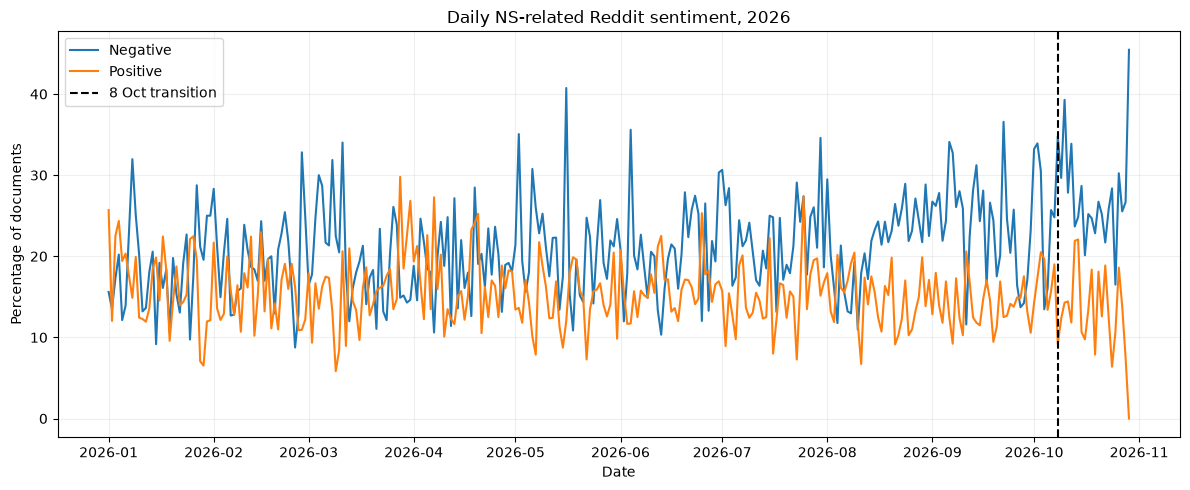

In [ ]:
overall = daily[daily["subreddit"] == "All"].sort_values("date")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(overall["date"],overall["pct_neg"] * 100,label="Negative",)
ax.plot(overall["date"],overall["pct_pos"] * 100,label="Positive",)
ax.axvline(pd.Timestamp("2026-10-08"),color="black",linestyle="--",label="8 Oct transition",)

ax.set(title="Daily NS-related Reddit sentiment, 2026",xlabel="Date",ylabel="Percentage of documents")

ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Overall, after event on 8 October:
* Negative sentiments increased by 5.8pp
* Neutral sentiments declined by 3.9pp
* Positive sentiments declined by 1.9pp
* Average negative probability increased by 0.047

However, this is driven largely by r/NationalServiceSG, where negative sentiments increased by 6.5pp. In r/Singapore and r/askSingapore, sentiments moved in the other direction (negative sentiment decreased/remained the same). These 2 subreddits have fewer post-event documents (200-300) than r/NationalServiceSG (2553), so estimates could be less precise. 

### Follow up 1: Sensitivity analysis - do results persist under equal window sizes?
* compare similar time periods before and after the event.

In [3]:
def load():
    doc = pd.read_parquet(DATA / "doc_sentiment.parquet")

    assert doc["doc_id"].is_unique
    print(f"Loaded {len(doc):,} documents")

    required = [
        "doc_id", "created_utc", "subreddit",
        "doc_type", "topic_macro",
        "sent_neg", "sent_neu", "sent_pos",
        "prob_buyin_committed", "prob_buyin_uncommitted",
        "prob_stance_supportive", "prob_stance_critical",
    ]
    missing = set(required) - set(doc.columns)
    assert not missing, f"Missing columns: {missing}"

    # Consistent Singapore calendar dates
    doc["created_utc"] = pd.to_datetime(
        doc["created_utc"], utc=True
    )
    doc["date"] = (
        doc["created_utc"]
        .dt.tz_convert("Asia/Singapore")
        .dt.tz_localize(None)
        .dt.normalize()
    )

    doc = doc.loc[
        doc["date"].dt.year.eq(2026)
    ].copy()

    # Exclude event day from before/after comparisons
    doc["period"] = np.select(
        [
            doc["date"] < EVENT_DATE,
            doc["date"] > EVENT_DATE,
        ],
        ["before", "after"],
        default="event_day",
    )

    # One dominant sentiment per document
    doc["sent_label"] = (
        doc[["sent_neg", "sent_neu", "sent_pos"]]
        .idxmax(axis=1)
        .str.replace("sent_", "", regex=False)
    )

    # Document-level net measures
    doc["net_buyin"] = (
        doc["prob_buyin_committed"]
        - doc["prob_buyin_uncommitted"]
    )
    doc["net_stance"] = (
        doc["prob_stance_supportive"]
        - doc["prob_stance_critical"]
    )

    print("Date range:", doc["date"].min(), "to", doc["date"].max())
    print(doc["period"].value_counts())

    return doc

In [4]:
DATA = Path(r'C:\Users\User1\NLP_Reddit_Sentiment_Analysis\data\processed\new')
EVENT_DATE = pd.Timestamp("2026-10-08")
doc = load()

def compare_window(doc, days):
    before = doc[(doc["date"] >= EVENT_DATE - pd.Timedelta(days=days)) & (doc["date"] < EVENT_DATE)].copy()
    after = doc[(doc["date"] > EVENT_DATE) & (doc["date"] <= EVENT_DATE + pd.Timedelta(days=days)) ].copy()

    rows = []

    for sub in ["All", *sorted(doc["subreddit"].dropna().unique())]:
        a = before if sub == "All" else before[before["subreddit"] == sub]
        b = after if sub == "All" else after[after["subreddit"] == sub]

        if a.empty or b.empty:
            continue

        rows.append({
            "window": days,
            "subreddit": sub,
            "n_before": len(a),
            "n_after": len(b),
            "neg_before": a["sent_label"].eq("neg").mean(),
            "neg_after": b["sent_label"].eq("neg").mean(),
            "change_neg_pp": 100 * (
                b["sent_label"].eq("neg").mean()
                - a["sent_label"].eq("neg").mean()
            ),
            "change_buyin": b["net_buyin"].mean() - a["net_buyin"].mean(),
            "change_stance": b["net_stance"].mean() - a["net_stance"].mean(),
        })

    return pd.DataFrame(rows)

window_results = pd.concat(
    [compare_window(doc, n) for n in [7, 14, 30]],
    ignore_index=True
)

display(window_results.round(3))

Loaded 55,065 documents
Date range: 2026-01-01 00:00:00 to 2026-10-29 00:00:00
period
before       51500
after         3108
event_day      457
Name: count, dtype: int64


,window,subreddit,n_before,n_after,neg_before,neg_after,change_neg_pp,change_buyin,change_stance
0,7,All,1309,1357,0.267,0.300,3.255,0.013,0.012
1,7,NationalServiceSG,1224,1179,0.270,0.285,1.456,0.006,0.015
2,7,askSingapore,31,46,0.161,0.283,12.132,0.013,0.048
3,7,singapore,54,132,0.259,0.439,18.013,0.064,-0.054
4,14,All,2668,2425,0.227,0.273,4.623,0.009,0.003
5,14,NationalServiceSG,2474,2047,0.226,0.265,3.891,0.004,0.002
6,14,askSingapore,98,186,0.184,0.231,4.751,-0.006,0.008
7,14,singapore,96,192,0.281,0.396,11.458,0.075,0.014
8,30,All,6925,3108,0.234,0.270,3.572,0.015,0.000
9,30,NationalServiceSG,6419,2553,0.229,0.260,3.022,0.005,-0.004


* short-lived spike in negativity: change is largest when comparing the week before and the week after the event. 
* r/Singapore shows the most consistent increase in negativity: in the 7, 14 and 30 day windows, negativity increased (by 18, 11 and 5 pp respectively)
* r/NationalServiceSG shows a smaller increase. negative sentiment rises by 1.5-3.9 points across the windows.
* r/askSingapore recovers quickly. it rises in the 7-day window, but decreases over the 30 day window.

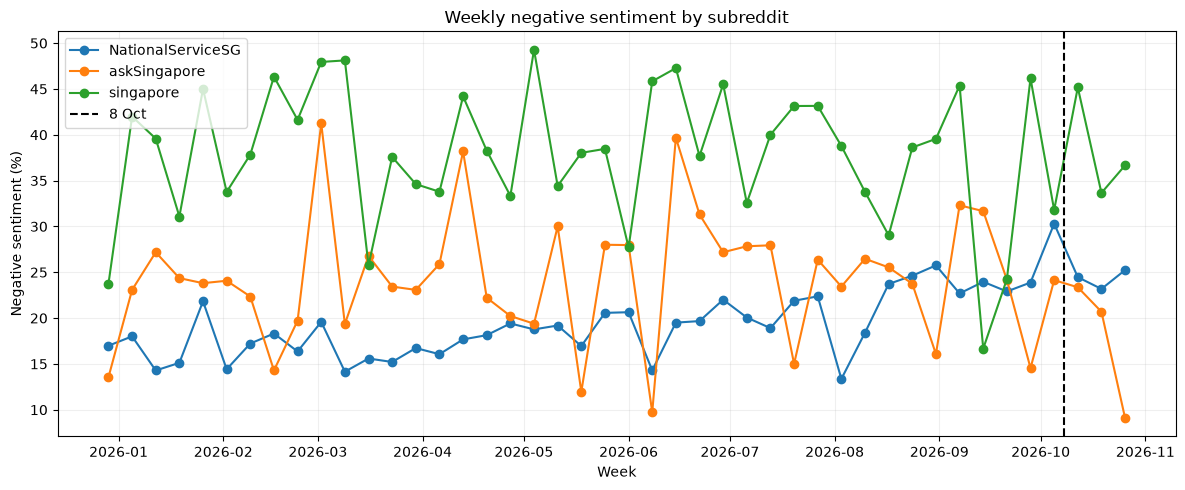

In [13]:
weekly = (
    doc.assign(
        week=doc["date"].dt.to_period("W-SUN").dt.start_time,
        is_negative=doc["sent_label"].eq("neg").astype(float)
    )
    .groupby(["week", "subreddit"])
    .agg(
        n=("doc_id", "size"),
        pct_negative=("is_negative", "mean"),
        mean_buyin=("net_buyin", "mean"),
        mean_stance=("net_stance", "mean"),
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 5))

for sub, g in weekly.groupby("subreddit"):
    g = g.sort_values("week")
    ax.plot(
        g["week"],
        g["pct_negative"] * 100,
        marker="o",
        label=sub
    )

ax.axvline(EVENT_DATE, color="black", linestyle="--", label="8 Oct")
ax.set(
    xlabel="Week",
    ylabel="Negative sentiment (%)",
    title="Weekly negative sentiment by subreddit"
)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

* in the first analysis, the full-data window increase in negative sentiments driven by r/NationalServiceSG is reflective of a general increasing trend of negative sentiments on that subreddit that has persisted since the start of the year.
* the event seems to have done little to change existing trends.

### Follow Up 2: Why did sentiments change?
* topic prevalence: did some topics become more prevalent after the event?
* within-topic sentiment: did sentiments about those topics become more negative?

In [31]:
WINDOW = 14 #can change
w = doc.loc[
    ((doc["date"] >= EVENT_DATE - pd.Timedelta(days=WINDOW)) & (doc["date"] < EVENT_DATE))
    | ((doc["date"] > EVENT_DATE) & (doc["date"] <= EVENT_DATE + pd.Timedelta(days=WINDOW)))].copy()

w["period"] = np.where(w["date"] < EVENT_DATE, "before", "after")
w["topic_macro"] = w["topic_macro"].fillna("Unassigned")
w["negative"] = w["sent_label"].eq("neg").astype(float)
w['positive'] = w['sent_label'].eq('pos').astype(float)

topic_summary = (w.groupby(["period", "topic_macro"]).agg(n=("doc_id", "size"),pct_negative=("negative", "mean")).reset_index())

topic_summary["share"] = (topic_summary["n"]/ topic_summary.groupby("period")["n"].transform("sum"))

wide = topic_summary.pivot(index="topic_macro",columns="period",values=["n", "share", "pct_negative"])

topic_changes = pd.DataFrame({
    "n_before": wide["n"]["before"],
    "n_after": wide["n"]["after"],
    "change_share_pp": 100 * (
        wide["share"]["after"] - wide["share"]["before"]
    ),
    "change_negative_pp": 100 * (
        wide["pct_negative"]["after"] - wide["pct_negative"]["before"]
    ),
}).sort_values("change_share_pp", ascending=False)

display(topic_changes.round(2))


display(w.groupby("period").agg(n=("doc_id", "size"),negative_pct=("negative", "mean")))

,n_before,n_after,change_share_pp,change_negative_pp
topic_macro,,,,
NS Policy & Society,156.0,217.0,3.10,-1.01
Mental Health,45.0,114.0,3.01,11.17
Gender & Diversity,20.0,77.0,2.43,1.95
Admin & Logistics,53.0,104.0,2.30,10.79
Physical Fitness & IPPT,100.0,138.0,1.94,14.46
Reservist & ICT,62.0,77.0,0.85,3.39
Career & Sign-on,47.0,63.0,0.84,-2.74
Discipline & Misconduct,168.0,163.0,0.42,5.84
Medical & Health,298.0,277.0,0.25,3.05


,n,negative_pct
period,,
after,2425,0.272990
before,2668,0.226762


**Qualitative Manual Review**
* Adjusted the above code to WINDOW=30 before running below

In [ ]:
TOPICS = [  "Gender & Diversity","Physical Fitness & IPPT","Mental Health","NS Policy & Society"]

w = w.loc[w["topic_macro"].isin(TOPICS)].copy()
negative = w.loc[w["sent_label"].eq("pos")]
samples = pd.concat([g.sample(min(10, len(g)), random_state=42) for _, g in negative.groupby(["topic_macro", "period"])], ignore_index=True)

print(samples.groupby(["topic_macro", "period"]).size())

chunks = pd.concat([pd.read_parquet(DATA / "comments_chunks.parquet",columns=["doc_id", "chunk_id", "text"]),
    pd.read_parquet(DATA / "submissions_chunks.parquet",columns=["doc_id", "chunk_id", "text"])], ignore_index=True)

# Retain only chunks marked eligible
eligibility = pd.read_parquet(DATA / "chunk_eligibility.parquet")
chunks = chunks.merge(eligibility[["chunk_id", "eligible_content"]],on="chunk_id",validate="one_to_one")
chunks = chunks.loc[chunks["eligible_content"]]

# Reconstruct text from chunks
# Note: this is not guaranteed to reproduce the original
# post/comment verbatim if chunking modified or repeated text.
doc_text = (chunks.groupby("doc_id")["text"].agg(lambda s: "\n\n".join(s.dropna().astype(str))).rename("text").reset_index())
samples = samples.merge(doc_text,on="doc_id",how="left",validate="one_to_one")
samples["interpretation"] = ""
samples["notes"] = ""

cols = ["doc_id","subreddit","date","period","topic_macro","sent_neg","sent_pos","text","interpretation","notes",]
samples[cols].to_csv( DATA / "topic_discussion_review.csv",index=False)

topic_macro              period
Gender & Diversity       after      3
                         before     5
Mental Health            after     10
                         before    10
NS Policy & Society      after     10
                         before    10
Physical Fitness & IPPT  after     10
                         before    10
dtype: int64


Comparing negative sentiment samples in the 30 days before and after the event, for the 4 topics that experienced the greatest percentage increase in popularity

Gender & Diversity became more negative
* Before: discussing dating and nationality-related fairness
* After: almost entirely arguing about whether women should be conscripted

Mental health became more positive
* Before & After: either giving or soliciting advice on mental health issues. 
* AfteR: pleas to ask for help if needed get stronger

NS Policy & Society became more positive
* Before & After: discussing the necessity of conscription and whether women should be conscripted

Physical Fitness & IPPT became more negative
* Before: fitness advice
* After: haze **unrelated to the 8th october incident but happened within the 30 day window. ignore.


**Is increase in negativity attributed to topic prevalence or topic sentiment?**
* Is contribution of a topic to overall negativity because it is a pre-existing negative topic that became more popular, or
* is it because sentiments about the topic itself became more negative?

In [29]:
def decompose_topics(data, sentiment = 'negative'):
    counts = (data.groupby(["topic_macro", "period"]).agg(n=("doc_id", "size"),p_neg=(sentiment, "mean")).unstack("period"))

    n = counts["n"].reindex(columns=["before", "after"]).fillna(0)
    p = counts["p_neg"].reindex(columns=["before", "after"])

    # For topics absent in one period, use pooled rate
    pooled = ((p.fillna(0) * n).sum(axis=1)/ n.sum(axis=1))
    p = p.T.fillna(pooled).T

    wb = n["before"] / n["before"].sum()
    wa = n["after"] / n["after"].sum()

    pb = p["before"]
    pa = p["after"]

    out = pd.DataFrame({
        "n_before": n["before"],
        "n_after": n["after"],
        "share_before": wb,
        "share_after": wa,
        "neg_before": pb,
        "neg_after": pa,
    })

    out["composition_pp"] = ((wa - wb) * (pa + pb) / 2 * 100)

    out["within_pp"] = ((pa - pb) * (wa + wb) / 2 * 100)

    out["total_pp"] = (out["composition_pp"] + out["within_pp"])

    actual_change = 100 * (data.loc[data["period"].eq("after"), sentiment].mean()- data.loc[data["period"].eq("before"), sentiment].mean())

    assert np.isclose(out["total_pp"].sum(),actual_change)

    return out.sort_values("total_pp", ascending=False)

In [38]:
decomp = decompose_topics(w)
decomp_pos = decompose_topics(w, 'positive')
decomp_full = pd.merge(decomp,decomp_pos,on='topic_macro', how='inner',suffixes=('_neg', '_pos'))
display(decomp_full[["n_before_neg","n_after_neg","composition_pp_neg","within_pp_neg","total_pp_neg","n_before_pos","n_after_pos","composition_pp_pos","within_pp_pos","total_pp_pos"]].round(3)        )

print("\nOVERALL DECOMPOSITION")
for x,y in [('negative', decomp),('positive', decomp_pos)]:
    print(f"Composition ({x}):", round(y["composition_pp"].sum(), 3), "pp")
    print(f"Within-topic ({x}):", round(y["within_pp"].sum(), 3), "pp")
    print(f"Total ({x}):", round(y["total_pp"].sum(), 3), "pp")

,n_before_neg,n_after_neg,composition_pp_neg,within_pp_neg,total_pp_neg,n_before_pos,n_after_pos,composition_pp_pos,within_pp_pos,total_pp_pos
topic_macro,,,,,,,,,,
Gender & Diversity,20,77,1.236,0.038,1.275,20,77,0.153,-0.145,0.008
NS Policy & Society,156,217,1.316,-0.075,1.241,156,217,0.203,-0.357,-0.154
Mental Health,45,114,0.704,0.357,1.061,45,114,0.612,0.161,0.772
Physical Fitness & IPPT,100,138,0.296,0.683,0.979,100,138,0.297,-0.350,-0.052
Admin & Logistics,53,104,0.385,0.339,0.724,53,104,0.263,-0.113,0.150
Discipline & Misconduct,168,163,0.141,0.380,0.521,168,163,0.032,0.054,0.086
Medical & Health,298,277,0.046,0.345,0.390,298,277,0.029,-0.100,-0.071
Unassigned,125,101,-0.116,0.483,0.368,125,101,-0.098,-0.096,-0.195
Reservist & ICT,62,77,0.207,0.093,0.300,62,77,0.131,0.225,0.356



OVERALL DECOMPOSITION
Composition (negative): 0.599 pp
Within-topic (negative): 4.024 pp
Total (negative): 4.623 pp
Composition (positive): -0.991 pp
Within-topic (positive): -0.093 pp
Total (positive): -1.084 pp


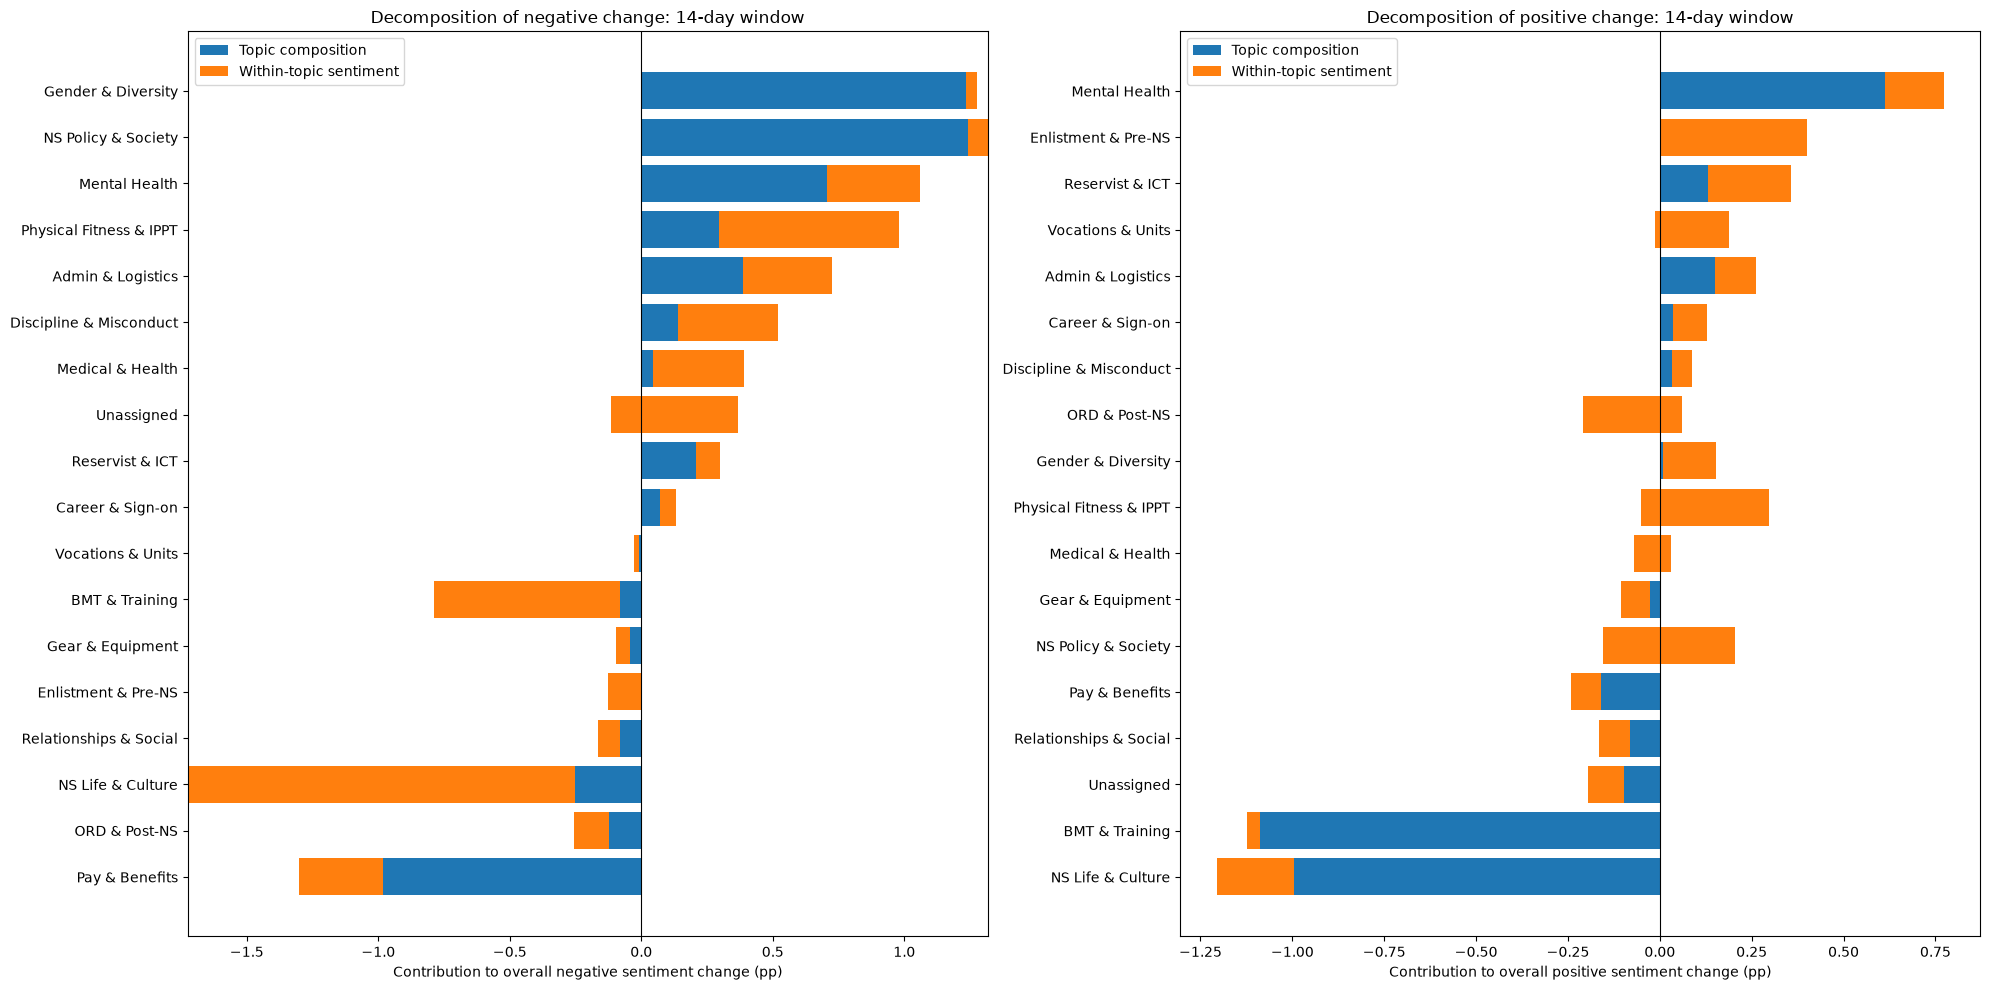

In [40]:
fig, ax = plt.subplots(nrows=1, ncols=2,figsize=(20, 10))
for i,j in [(0,'negative'),(1,'positive')]:
    plot_df = decomp_full.sort_values(f"total_pp_{j[:3]}")
    ax[i].barh(plot_df.index,plot_df[f"composition_pp_{j[:3]}"],label="Topic composition")
    ax[i].barh(plot_df.index,plot_df[f"within_pp_{j[:3]}"],left=plot_df[f"composition_pp_{j[:3]}"],label="Within-topic sentiment")
    ax[i].axvline(0, color="black", linewidth=0.8)
    ax[i].set(xlabel=f"Contribution to overall {j} sentiment change (pp)",title=f"Decomposition of {j} change: {WINDOW}-day window")
    ax[i].legend()
plt.tight_layout()
plt.show()

In [41]:
results = []

for sub in ["All", *sorted(w["subreddit"].unique())]:
    subset = w if sub == "All" else w[w["subreddit"] == sub]

    d = pd.merge(decompose_topics(subset),decompose_topics(subset,'positive'),on='topic_macro', how='inner',suffixes=('_neg', '_pos'))

    results.append({"subreddit": sub,
        "sample_size_neg": d.n_before_neg.sum() + d.n_after_neg.sum(),"composition_pp_neg": d["composition_pp_neg"].sum(),"within_pp_neg": d["within_pp_neg"].sum(),"total_pp_neg": d["total_pp_neg"].sum(),
        "sample_size_pos": d.n_before_pos.sum() + d.n_after_pos.sum(),"composition_pp_pos": d["composition_pp_pos"].sum(),"within_pp_pos": d["within_pp_pos"].sum(),"total_pp_pos": d["total_pp_pos"].sum(),
    })

subreddit_decomp = pd.DataFrame(results)

display(subreddit_decomp.round(3))

,subreddit,sample_size_neg,composition_pp_neg,within_pp_neg,total_pp_neg,sample_size_pos,composition_pp_pos,within_pp_pos,total_pp_pos
0,All,5093.0,0.599,4.024,4.623,5093.0,-0.991,-0.093,-1.084
1,NationalServiceSG,4521.0,0.878,3.013,3.891,4521.0,-0.904,0.063,-0.841
2,askSingapore,284.0,-1.031,5.782,4.751,284.0,-7.416,10.499,3.083
3,singapore,288.0,0.686,10.773,11.458,288.0,0.242,-5.971,-5.729
